<a href="https://colab.research.google.com/github/DiegoMartell/Deep-Learning/blob/main/Hands-on/Hands-on-3-MLP-Penguins.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on 3 MLP-Penguins

## 1. Fundamentos Teóricos del Perceptrón Multicapa
Un **Perceptrón Multicapa (MLP)** es una red neuronal artificial de alimentación hacia adelante (*feedforward*) compuesta por al menos tres capas de nodos:
1. **Capa de Entrada (Input Layer):** Recibe las características (*features*) que describen cada patrón.
2. **Capas Ocultas (Hidden Layers):** Capas intermedias que transforman las entradas mediante combinaciones lineales y funciones de activación no lineales. A diferencia del perceptrón simple (limitado a fronteras lineales), las capas ocultas permiten "doblar" y deformar el espacio matemático para encerrar o separar patrones complejos o no lineales.
3. **Capa de Salida (Output Layer):** Produce la clasificación o predicción final del modelo.

## 2. Modelo Matemático del MLP

### Ecuación Fundamental del Neurón
La salida predicha por una neurona en cualquier capa se calcula mediante la combinación lineal de sus entradas y el paso por una función de activación no lineal:

$$\hat{y} = \phi \left( \sum_{i=1}^{n} w_i x_i + b \right) = \phi (W^T X + b)$$

**Desglose de variables:**
* **$X$ (Vector de Entradas):** Características cuantitativas del patrón.
* **$W$ (Pesos):** Ponderan la importancia relativa de cada entrada hacia la neurona.
* **$b$ (Sesgo / Bias):** Permite desplazar la función de activación en el espacio, otorgando flexibilidad geométrica.
* **$\phi$ (Función de Activación):** Introduce la no-linealidad necesaria para aprender fronteras complejas (ej. **ReLU**: $f(z) = \max(0, z)$ o **Sigmoide**: $\sigma(z) = \frac{1}{1 + e^{-z}}$).

### Función de Pérdida y Aprendizaje
Para evaluar el error en clasificación multiclase se utiliza la **Entropía Cruzada (Log Loss)**, que penaliza fuertemente las predicciones incorrectas realizadas con alta certeza:

$$J(w) = - \frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

El ajuste de los pesos $W$ y sesgos $b$ se realiza iterativamente a través del algoritmo de **Retropropagación (*Backpropagation*)** y el optimizador **Adam**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Módulos de Scikit-Learn para el pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.inspection import DecisionBoundaryDisplay

print("Librerías cargadas exitosamente.")

✅ Librerías cargadas exitosamente.


## 3. Pipeline de Machine Learning

### 3.1 Selección y Descripción del Dataset Palmer Penguins
Emplearemos el **Dataset Palmer Penguins**, el cual contiene mediciones anatómicas de 3 especies de pingüinos de la Antártida (*Adelie*, *Chinstrap* y *Gentoo*):
* **Características cuantitativas ($X$):** `bill_length_mm` (longitud del pico), `bill_depth_mm` (profundidad del pico), `flipper_length_mm` (longitud de la aleta) y `body_mass_g` (masa corporal en gramos).
* **Variable objetivo ($Y$):** `species` (especie de pingüino a predecir).

### Explicación de selección e indexación de columnas
A diferencia de Iris, este conjunto posee filas con valores nulos y nombres de columna explícitos. Por ello, primero aplicamos la limpieza de datos nulos con `.dropna()` y luego seleccionamos la matriz de características y el vector etiqueta:

1. **Matriz de Características ($X$):** `df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']]` (4 variables cuantitativas independientes).
2. **Vector Objetivo ($Y$):** `df['species']` (etiqueta con las 3 especies).

Primeras 5 filas del dataset Palmer Penguins:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007



Dimensiones de la matriz X: (342, 4)
Clases únicas en Y: ['Adelie' 'Gentoo' 'Chinstrap']


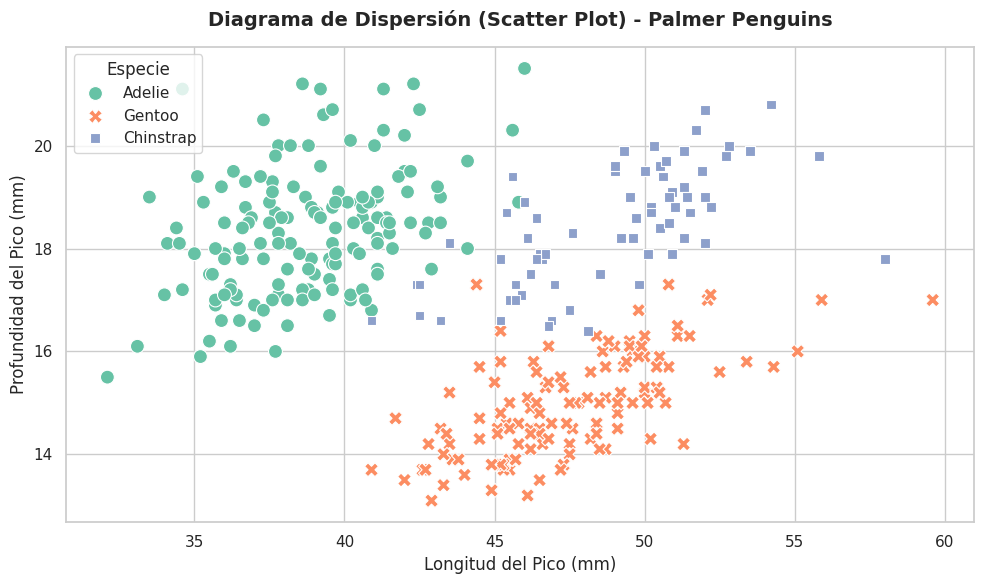

In [2]:
# 1. Carga del conjunto de datos desde la URL pública
url = "https://raw.githubusercontent.com/mcnakhaee/palmerpenguins/master/palmerpenguins/data/penguins.csv"
df = pd.read_csv(url)

# Variables de entrada y variable objetivo
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
target = 'species'

# Limpieza de filas con datos faltantes (NaN)
df = df.dropna(subset=features + [target]).reset_index(drop=True)

# Visualizar las primeras 5 filas
print("Primeras 5 filas del dataset Palmer Penguins:")
display(df.head())

# Separación en X (Características) e Y (Etiqueta)
X = df[features]
Y = df[target]

print(f"\nDimensiones de la matriz X: {X.shape}")
print(f"Clases únicas en Y: {Y.unique()}")

# 2. Diagrama de Dispersión (Scatter Plot)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='species',
    style='species',
    s=100,
    palette='Set2'
)
plt.title('Diagrama de Dispersión (Scatter Plot) - Palmer Penguins', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitud del Pico (mm)', fontsize=12)
plt.ylabel('Profundidad del Pico (mm)', fontsize=12)
plt.legend(title='Especie', loc='upper left')
plt.tight_layout()
plt.show()

### 3.2 Preprocesamiento de Datos

1. **División (*Splitting*):** Empleamos `train_test_split` reservando el **20%** de las muestras (`test_size=0.20`) para validación no vista y el **80%** para entrenamiento. Usamos `stratify=Y` para mantener equilibrada la proporción de cada especie de pingüino en ambos subconjuntos.

2. **Escalado de Características (*Scaling*):** En Palmer Penguins, las variables están en órdenes de magnitud muy dispares (la masa corporal supera los 3,000 g mientras que el pico está entre 15 y 55 mm). Las redes neuronales son extremadamente sensibles a las diferencias de escala. Aplicamos `StandardScaler` para estandarizar los datos a media $\mu=0$ y desviación estándar $\sigma=1$:
   $$z = \frac{x - \mu}{\sigma}$$
   * Se ejecuta `fit_transform` sobre $X_{train}$ para calcular media y desviación.
   * Se ejecuta únicamente `transform` sobre $X_{test}$ para evitar la fuga de información (*data leakage*).

In [3]:
# 1. División del dataset (80% entrenamiento, 20% prueba)
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

# 2. Escalado Estándar
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datos escalados y divididos correctamente:")
print(f"Muestras de entrenamiento: {X_train_scaled.shape}")
print(f"Muestras de prueba: {X_test_scaled.shape}")

Datos escalados y divididos correctamente:
Muestras de entrenamiento: (273, 4)
Muestras de prueba: (69, 4)


### 3.3 Selección y Entrenamiento del Clasificador MLP
Configuramos e instanciamos la clase `MLPClassifier` de Scikit-Learn:
* `hidden_layer_sizes=(10, 10)`: Define una arquitectura de 2 capas ocultas con 10 neuronas cada una.
* `activation='relu'`: Utiliza la función rectificadora lineal para añadir capacidad de aprendizaje no lineal.
* `solver='adam'`: Aplica el algoritmo de optimización estocástico basado en el gradiente.
* `max_iter=1000`: Establece el límite de iteraciones (épocas) de entrenamiento.

In [4]:
# Instanciación del Clasificador MLP
mlp = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    max_iter=1000,
    activation='relu',
    solver='adam',
    random_state=42
)

# Entrenamiento de la red neuronal mediante Backpropagation
print("Entrenando el Perceptrón Multicapa...")
mlp.fit(X_train_scaled, Y_train)
print(f"✅ Entrenamiento completado en {mlp.n_iter_} iteraciones.")

Entrenando el Perceptrón Multicapa...
✅ Entrenamiento completado en 392 iteraciones.


### 3.4 Evaluación del Modelo
Evaluamos el desempeño del modelo sobre el conjunto de prueba no visto ($X_{test\_scaled}$):
1. **Accuracy (Exactitud global):** Porcentaje total de clasificaciones acertadas.
2. **Matriz de Confusión (`confusion_matrix`):** Muestra el desglose de aciertos y errores entre especies reales vs. predichas.
3. **Reporte de Clasificación (`classification_report`):** Incluye métricas detalladas de precisión, sensibilidad (*recall*) y *F1-score* por especie.
4. **Frontera de Decisión 2D:** Visualización interactiva de cómo la red neuronal fragmenta el espacio matemático entre las especies utilizando 2 dimensiones clave (`bill_length_mm` y `bill_depth_mm`).

🎯 Exactitud (Accuracy) del Modelo: 100.00%

--- MATRIZ DE CONFUSIÓN ---
[[30  0  0]
 [ 0 14  0]
 [ 0  0 25]]

--- REPORTE COMPLETO DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



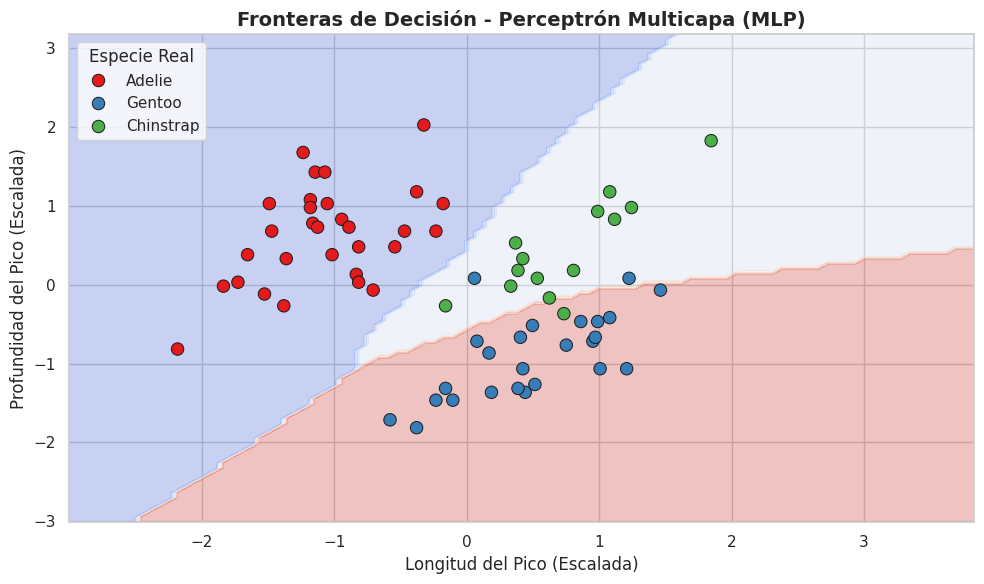

In [5]:
# 1. Predicciones en el conjunto de prueba
predictions = mlp.predict(X_test_scaled)

# 2. Cálculo de métricas
accuracy = accuracy_score(Y_test, predictions)
print(f"🎯 Exactitud (Accuracy) del Modelo: {accuracy * 100:.2f}%\n")

print("--- MATRIZ DE CONFUSIÓN ---")
conf_matrix = confusion_matrix(Y_test, predictions)
print(conf_matrix)

print("\n--- REPORTE COMPLETO DE CLASIFICACIÓN ---")
print(classification_report(Y_test, predictions))

# 3. Graficación de Fronteras de Decisión en 2D
# Seleccionamos las columnas 0 y 1 (bill_length_mm y bill_depth_mm)
X_train_2d = X_train_scaled[:, 0:2]
X_test_2d = X_test_scaled[:, 0:2]

mlp_2d = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    max_iter=1000,
    activation="relu",
    solver="adam",
    random_state=42
)
mlp_2d.fit(X_train_2d, Y_train)

plt.figure(figsize=(10, 6))
DecisionBoundaryDisplay.from_estimator(
    mlp_2d,
    X_train_2d,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.3,
    ax=plt.gca()
)

sns.scatterplot(
    x=X_test_2d[:, 0],
    y=X_test_2d[:, 1],
    hue=Y_test,
    palette="Set1",
    edgecolor="k",
    s=80
)
plt.title("Fronteras de Decisión - Perceptrón Multicapa (MLP)", fontsize=14, fontweight="bold")
plt.xlabel("Longitud del Pico (Escalada)", fontsize=12)
plt.ylabel("Profundidad del Pico (Escalada)", fontsize=12)
plt.legend(title="Especie Real", loc="upper left")
plt.tight_layout()
plt.show()